In [1]:
import numpy as np
data = np.load('../tf_flowers_prepared.npz')

X_train = data['X_train']
y_train = data['y_train']

X_val = data['X_val']
y_val = data['y_val']

X_test = data['X_test']
y_test = data['y_test']

class_labels = data['class_names'].tolist()

In [3]:
# Flatten
X_train_knn = X_train.reshape(len(X_train), -1)
X_val_knn = X_val.reshape(len(X_val), -1)
X_test_knn = X_test.reshape(len(X_test), -1)

print("Train:", X_train_knn.shape)
print("Validation:", X_val_knn.shape)
print("Test:", X_test_knn.shape)

Train: (1080, 67500)
Validation: (360, 67500)
Test: (360, 67500)


In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [1, 3, 5, 7, 9]

metrics = {
    'L1 (Manhattan)': 'manhattan',
    'L2 (Euclidean)': 'euclidean'
}

results = []

for metric_name, metric_value in metrics.items():

    for k in k_values:

        # Création du modèle
        knn = KNeighborsClassifier(
            n_neighbors=k,
            metric=metric_value,
            n_jobs=-1
        )

        # Apprentissage sur le jeu d'entraînement
        knn.fit(X_train_knn, y_train)

        # Prédiction sur le jeu de validation
        y_val_pred = knn.predict(X_val_knn)

        # Calcul de l'accuracy
        val_accuracy = accuracy_score(y_val, y_val_pred)

        results.append({
            'K': k,
            'Distance': metric_name,
            'Validation Accuracy': val_accuracy
        })

        print(
            f"K={k}, Distance={metric_name}, "
            f"Validation Accuracy={val_accuracy:.4f}"
        )

K=1, Distance=L1 (Manhattan), Validation Accuracy=0.4972
K=3, Distance=L1 (Manhattan), Validation Accuracy=0.5139
K=5, Distance=L1 (Manhattan), Validation Accuracy=0.5278
K=7, Distance=L1 (Manhattan), Validation Accuracy=0.5333
K=9, Distance=L1 (Manhattan), Validation Accuracy=0.5417
K=1, Distance=L2 (Euclidean), Validation Accuracy=0.4667
K=3, Distance=L2 (Euclidean), Validation Accuracy=0.4639
K=5, Distance=L2 (Euclidean), Validation Accuracy=0.5028
K=7, Distance=L2 (Euclidean), Validation Accuracy=0.4889
K=9, Distance=L2 (Euclidean), Validation Accuracy=0.4917


In [8]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Validation Accuracy',
    ascending=False
)

print(results_df)

   K        Distance  Validation Accuracy
4  9  L1 (Manhattan)             0.541667
3  7  L1 (Manhattan)             0.533333
2  5  L1 (Manhattan)             0.527778
1  3  L1 (Manhattan)             0.513889
7  5  L2 (Euclidean)             0.502778
0  1  L1 (Manhattan)             0.497222
9  9  L2 (Euclidean)             0.491667
8  7  L2 (Euclidean)             0.488889
5  1  L2 (Euclidean)             0.466667
6  3  L2 (Euclidean)             0.463889


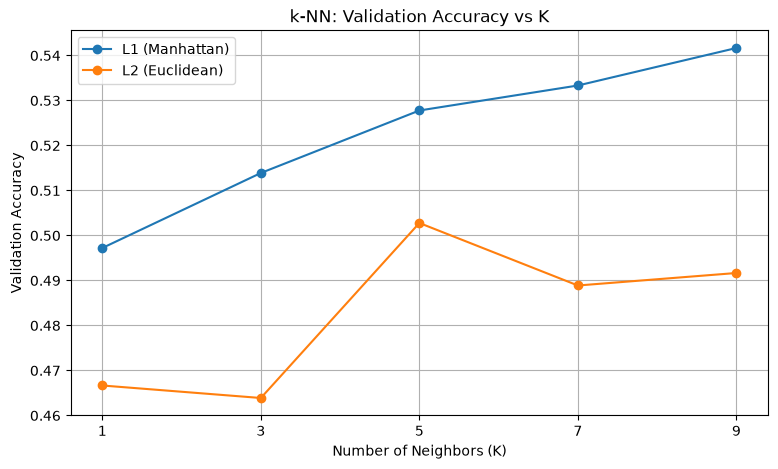

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric_name in metrics.keys():

    subset = results_df[
        results_df['Distance'] == metric_name
    ].sort_values('K')

    plt.plot(
        subset['K'],
        subset['Validation Accuracy'],
        marker='o',
        label=metric_name
    )

plt.title('k-NN: Validation Accuracy vs K')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Validation Accuracy')
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()